# 1. Implementación del Algoritmo de Grover

- Este algoritmo trata de encontrar un elemento concreto en una lista de elementos desordenados. Presenta una complejidad temporal de O($\sqrt{n}$), y no O(n). Es decir, se produce una mejora cuadrática, y deja de escalar linealmente según el tamaño del problema.

## 1.1 Conexión con IBM Quantum

In [ ]:
!pip install -q qiskit qiskit-aer matplotlib pylatexenc

In [ ]:
!pip install -q qiskit-ibm-runtime
!pip install -q "python-dateutil<3.0,>=2.8.2"
# Ignorar el ERROR. Ocurre porque ibm_cloud_sdk_core necesita una versión más reciente de python, que la preinstalada por Colab.

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
google-cloud-bigquery 3.46.2 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 3.0.0 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
holidays 0.107 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 3.0.0 which is incompatible.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ibm-cloud-sdk-core 3.28.1 requires python_dateutil<3.1.0,>=3.0.0, bu

In [ ]:
import qiskit
from qiskit_ibm_runtime import QiskitRuntimeService
from google.colab import userdata
ref1 = str(userdata.get('ref1'))

# Usamos la plataforma clásica de IBM Quantum, también podría ser ibm_cloud:
QiskitRuntimeService.save_account(channel="ibm_quantum_platform", token=ref1, overwrite=True)

# Probamos a inicializarlo y listar los simuladores/backends disponibles
service = QiskitRuntimeService()
print("¡Conectado con éxito!")
print(service.backends())

qiskit_runtime_service.__init__:WARNING:2026-11-03 17:54:39,988: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Santiago-server. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-03 17:54:39,997: Loading instance: Santiago-server, plan: open


¡Conectado con éxito!
[<IBMBackend('ibm_fez')>, <IBMBackend('ibm_kingston')>, <IBMBackend('ibm_marrakesh')>]


## 1.2 Diseñar el circuito cuántico

Antes de diseñar el circuito, hay que diseñar el Oráculo, que es otro circuito. Este se encargará de decir qué estado es el que estamos buscando como solución, y cuales no. En este caso el Oráculo será sencillo. Invertirá la amplitud del estado que estamos buscando, y en cambio, dejará inalteradas las amplitudes de los otros estados. En esta implementación le estamos "dando" la solución al oráculo, pero en un problema real, esto no sería así.

El circuito completo es:
- Aplicar puertas H a todos los qubits para poner todos los estados en superposición (es decir, que todos los estados sean igualmente probables, o que sus amplitudes tengan el mismo valor). Por ejemplo, para 4 qubits, la amplitud de cada estado pasaría a valer 1/$\sqrt{16}$ = 0.25 (y cada prob 1/($\sqrt{16}$)² = 1/16 = 0.0625).
- Luego, el Oráculo da la vuelta (pone en negativo) a las amplitudes que son solución.
- Y después de esto, calculamos la media de las amplitudes, y aplicamos la difusión. Es decir, para cada estado, nueva amplitud = 2*media - amplitud.


Por ejemplo, para 4 qubits, llamemos $a$ = 1/$\sqrt{16}$ = 0.25 a la amplitud inicial de cada estado.
1. Después de las H: los 16 estados valen $a$.
2. Después del oráculo: 15 estados siguen en a, y 1 pasa a $-a$.
3. Calculamos la media de las 16 amplitudes. media = (15*a + 1*(-a))/16 = 14a/16 = 7a/8 = 0.21875.
4. $Reflejamos$ cada amplitud respecto a esa media, con la fórmula antes mencionada (nueva amplitud = 2*media - amplitud).
- Amplitudes normales (valían a): 2*(0.21875) - a = 0.4375-a = 0.1875
- Amplitudes marcadas por el oráculo: 2*(0.21875) - (-a) = 0.4375+a= 0.6875

5. Comprobación.
- La probabilidad del estado marcado es = |0.6875|², es decir, (0.6875)² = 0.4727.
- Y la prob de cualquier otro estado es = |0.1875|² = 0,0352.

De hecho, 0.4727 + 15*0.0352 = 0.4727 + 0,528 = 1.0007. No da 1 exacto porque he redondeado en el cálculo.


Por tanto, el circuito completo es:
H en todos → oráculo (Detector) → difusión (Grover) → medir.
Una sola iteración de Grover sería: oráculo + difusión.

Para 1 estado marcado en el oráculo entre 16, una sola iteración no llega al 100 %. Esto coincide con la fórmula del ángulo: sin θ = 1/√16 = 1/4, y tras una iteración la probabilidad es sin²(3θ) ≈ 0,473. Para 4 qubits lo óptimo son unas 3 iteraciones (≈ (π/4)·√16), con ≈ 96 % de acierto. Ahí está la gracia de Grover: se repite el bloque oráculo + difusión.

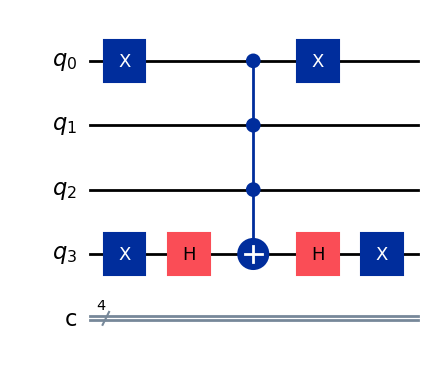

In [ ]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# 1. Definir el Oráculo / Detector
Detector = QuantumCircuit(4,4)

# Queremos que el oráculo encuentre, e invierta el estado deseado. En este caso, será el 1111, por ejemplo.
# Para esto usaremos una puerta Z con 3 controles y objetivo q3, que cambia el signo solo de 1111.
# Qiskit no tiene cccz directa, pero podemos construirla así:

# H sobre el objetivo + Toffoli de 3 controles + H. Las H convierten “voltear” en “poner un signo −”, y los controles hacen que eso solo pase para 1111.
"""
Detector.h(3)
Detector.mcx([0, 1, 2], 3)
Detector.h(3)
"""
# También podríamos comentar el anterior oráculo, y probar este otro, para que el estado que buscamos sea el 0110.
Detector.x([0, 3])                 # convierte 0110 en 1111
Detector.h(3)
Detector.mcx([0, 1, 2], 3)         # Z con 3 controles
Detector.h(3)
Detector.x([0, 3])                 # deshace la conversión

Detector.draw(output = 'mpl')

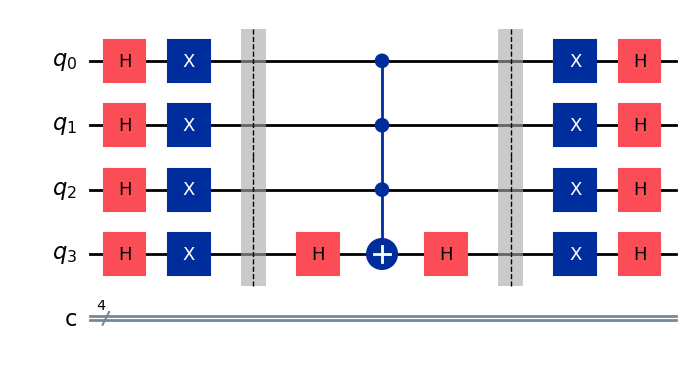

In [ ]:
# 2. Implementar la puerta de Grover, para la difusión
Grover = QuantumCircuit(4, 4)

Grover.h(range(4))
Grover.x(range(4))

Grover.barrier(range(4))
Grover.h(3)
Grover.mcx([0, 1, 2], 3)           # cambia el signo solo de 1111
Grover.h(3)
Grover.barrier(range(4))

Grover.x(range(4))
Grover.h(range(4))

Grover.draw(output = 'mpl')

# La lógica es la de antes: las H y las X llevan el estado de superposición uniforme a 1111, ahí cambiamos el signo, y luego deshacemos las conversiones.
# El resultado es la reflexión respecto a la media.

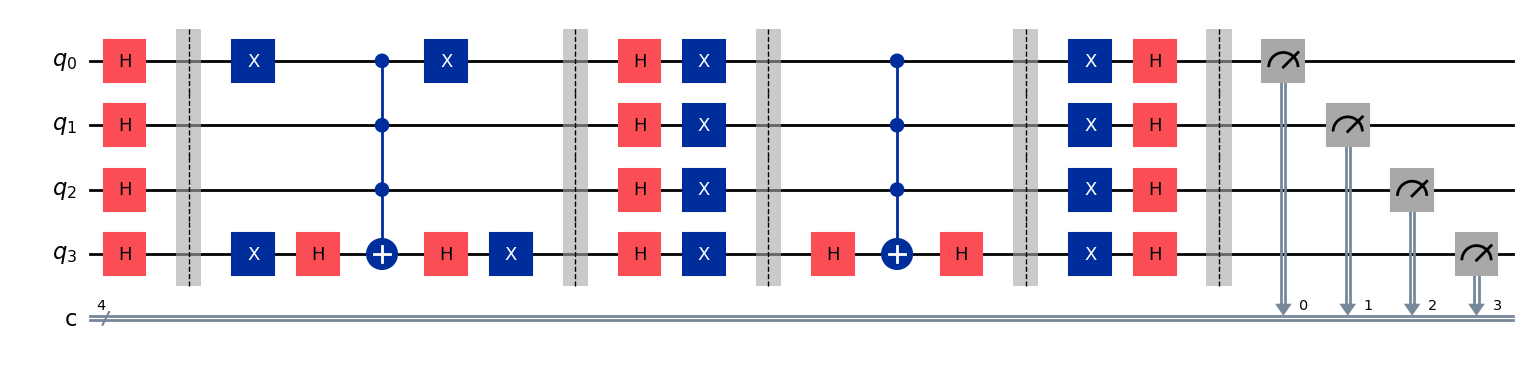

In [ ]:
circ = QuantumCircuit(4,4)
circ.h(range(4))

circ.barrier(range(4))
circ = circ.compose(Detector)

circ.barrier(range(4))
circ = circ.compose(Grover)

circ.barrier(range(4))
circ.measure(range(4), range(4))
circ.draw(output='mpl')

Resultados de la medición: {'1010': 29, '1101': 40, '0100': 30, '0000': 37, '0010': 38, '1111': 36, '0001': 32, '1100': 31, '0110': 465, '1000': 39, '0011': 35, '0111': 30, '1011': 43, '1001': 44, '0101': 36, '1110': 35}


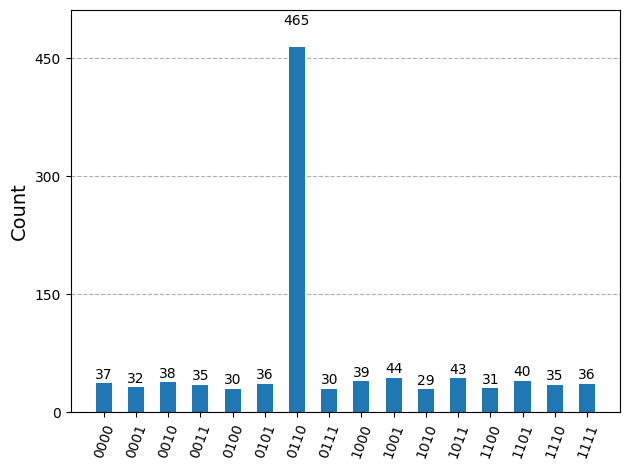

In [ ]:
# 1. Inicializamos el simulador.
simulator = AerSimulator()

# 2. Ejecutamos el circuito directamente.
job = simulator.run(circ, shots=1000)
result = job.result()
counts = result.get_counts()

# 3. Mostramos el resultado y el histograma.
print("Resultados de la medición:", counts)
plot_histogram(counts)